## **T9: Support Vector Machine (SVM) — Apple Products Dataset**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC, SVR
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    mean_squared_error, r2_score
)

# Upload the Apple CSV file in Google Colab
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Saving apple_products_pricing_2020_2026.csv to apple_products_pricing_2020_2026.csv
Dataset shape: (80000, 14)
Columns: ['Date', 'Platform', 'Product_Category', 'Model_Name', 'Condition', 'Launch_Price_USD', 'Launch_Price_INR', 'Current_Price_USD', 'Current_Price_INR', 'Discount_Pct', 'Sale_Event', 'Stock_Status', 'Rating', 'Reviews_Count']


,Date,Platform,Product_Category,Model_Name,Condition,Launch_Price_USD,Launch_Price_INR,Current_Price_USD,Current_Price_INR,Discount_Pct,Sale_Event,Stock_Status,Rating,Reviews_Count
0,2020-09-19,Flipkart,Watch,Apple Watch Series 6 (44mm),New,429,42042,435.81,43322.41,-1.6,NaN,In Stock,4.7,40
1,2020-09-20,Flipkart,Watch,Apple Watch Series 6 (44mm),New,429,42042,436.49,42320.43,-1.7,NaN,Out of Stock,4.6,84
2,2020-09-23,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,422.73,40879.36,1.5,NaN,In Stock,4.4,110
3,2020-09-23,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,425.00,42008.70,0.9,NaN,In Stock,4.8,111
4,2020-09-24,Amazon,Watch,Apple Watch Series 6 (44mm),New,429,42042,436.22,41984.28,-1.7,NaN,In Stock,4.7,35


## **1. Data Preparation**

In [2]:
required_columns = ['Launch_Price_INR', 'Current_Price_INR', 'Stock_Status']

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"These required columns were not found: {missing_columns}. Check the printed column names.")

svm_df = df[required_columns].copy()

svm_df['Launch_Price_INR'] = pd.to_numeric(svm_df['Launch_Price_INR'], errors='coerce')
svm_df['Current_Price_INR'] = pd.to_numeric(svm_df['Current_Price_INR'], errors='coerce')
svm_df = svm_df.dropna()

# Small sample for faster execution
svm_df = svm_df.sample(n=min(1000, len(svm_df)), random_state=42)

encoder = LabelEncoder()
y = encoder.fit_transform(svm_df['Stock_Status'].astype(str))
X = svm_df[['Launch_Price_INR', 'Current_Price_INR']]

print("Sample size:", len(svm_df))
print("Stock status classes:", list(encoder.classes_))
print(svm_df.head())

Sample size: 1000
Stock status classes: ['In Stock', 'Low Stock', 'Out of Stock']
       Launch_Price_INR  Current_Price_INR Stock_Status
47044            107702          107480.49     In Stock
44295            117502           96246.04     In Stock
74783             78302           36865.41     In Stock
70975            107702           97344.40     In Stock
46645             42042           32091.76     In Stock


## **2. Standardization and Train-Test Split**

In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y if len(np.unique(y)) > 1 else None
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


## **3. Compare Linear, RBF, and Polynomial Kernels**

In [4]:
kernels = ['linear', 'rbf', 'poly']
models = {}
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0, gamma='scale')
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    models[kernel] = model
    results.append({
        'Kernel': kernel.upper(),
        'Accuracy': accuracy_score(y_test, prediction),
        'Support Vectors': len(model.support_vectors_)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Kernel  Accuracy  Support Vectors
LINEAR     0.705              373
   RBF     0.705              569
  POLY     0.705              393


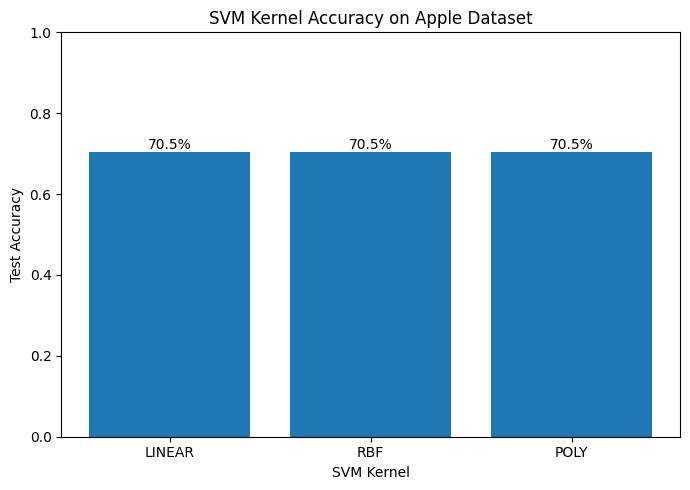

In [5]:
# Accuracy comparison graph
plt.figure(figsize=(7, 5))
bars = plt.bar(results_df['Kernel'], results_df['Accuracy'])
plt.title('SVM Kernel Accuracy on Apple Dataset')
plt.xlabel('SVM Kernel')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)

for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:.1%}',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

## **4. Non-Linear Decision Boundary and Support Vectors**

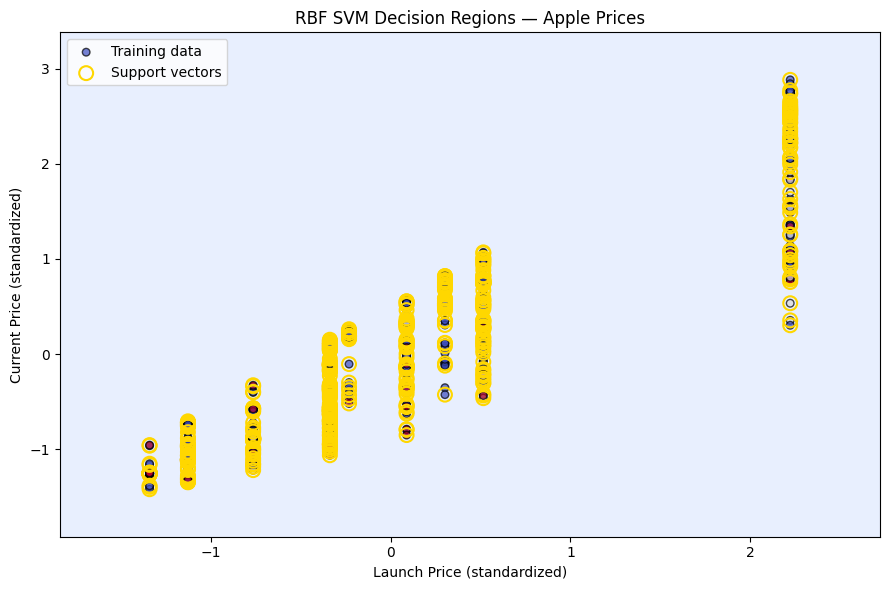

In [6]:
# Train an RBF SVM on the two scaled price features
rbf_model = SVC(kernel='rbf', C=1.0, gamma='scale')
rbf_model.fit(X_train, y_train)

# Build a grid for plotting the decision regions
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = rbf_model.predict(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.2, cmap='coolwarm')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm',
            edgecolors='black', s=30, alpha=0.7, label='Training data')

support_vectors = rbf_model.support_vectors_
plt.scatter(support_vectors[:, 0], support_vectors[:, 1],
            s=100, facecolors='none', edgecolors='gold',
            linewidths=1.5, label='Support vectors')

plt.title('RBF SVM Decision Regions — Apple Prices')
plt.xlabel('Launch Price (standardized)')
plt.ylabel('Current Price (standardized)')
plt.legend()
plt.tight_layout()
plt.show()

## **5. Small Hyperparameter Search**

In [7]:
param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.1, 1, 10],
    'gamma': ['scale']
}

grid = GridSearchCV(
    SVC(),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_test, best_pred))
print("\nClassification report:\n",
      classification_report(y_test, best_pred, labels=np.unique(y), zero_division=0))

Best parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best cross-validation accuracy: 0.7063
Test accuracy: 0.705

Confusion matrix:
 [[141   0   0]
 [ 28   0   0]
 [ 31   0   0]]

Classification report:
               precision    recall  f1-score   support

           0       0.70      1.00      0.83       141
           1       0.00      0.00      0.00        28
           2       0.00      0.00      0.00        31

    accuracy                           0.70       200
   macro avg       0.23      0.33      0.28       200
weighted avg       0.50      0.70      0.58       200



## **6. Support Vector Regression (SVR)**

SVR RMSE: 42141.64
SVR R2 score: -0.046


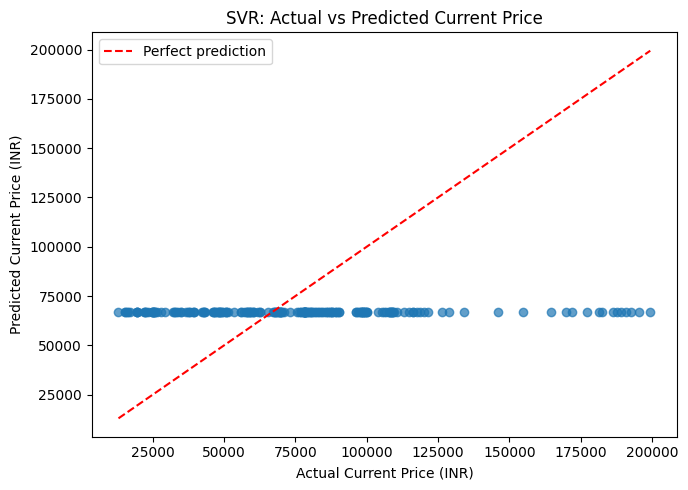

In [8]:
reg_df = df[['Launch_Price_INR', 'Current_Price_INR']].copy()
reg_df['Launch_Price_INR'] = pd.to_numeric(reg_df['Launch_Price_INR'], errors='coerce')
reg_df['Current_Price_INR'] = pd.to_numeric(reg_df['Current_Price_INR'], errors='coerce')
reg_df = reg_df.dropna().sample(n=min(1000, len(reg_df.dropna())), random_state=42)

X_reg = reg_df[['Launch_Price_INR']]
y_reg = reg_df['Current_Price_INR']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_scaler = StandardScaler()
Xr_train_scaled = reg_scaler.fit_transform(Xr_train)
Xr_test_scaled = reg_scaler.transform(Xr_test)

svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr.fit(Xr_train_scaled, yr_train)
yr_pred = svr.predict(Xr_test_scaled)

rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
print("SVR RMSE:", round(rmse, 2))
print("SVR R2 score:", round(r2_score(yr_test, yr_pred), 3))

# Actual vs predicted price graph
plt.figure(figsize=(7, 5))
plt.scatter(yr_test, yr_pred, alpha=0.7)
lower = min(yr_test.min(), yr_pred.min())
upper = max(yr_test.max(), yr_pred.max())
plt.plot([lower, upper], [lower, upper], 'r--', label='Perfect prediction')
plt.title('SVR: Actual vs Predicted Current Price')
plt.xlabel('Actual Current Price (INR)')
plt.ylabel('Predicted Current Price (INR)')
plt.legend()
plt.tight_layout()
plt.show()